# Dopamine mice: how learning progressed
Oct 2026 \
author: Inês Laranjeira (drafted with Claude)

Companion to `0_data_availability.ipynb` (which shows *what data* each session has); this shows *how the mouse did*, session by session, for every mouse with DA photometry.

**Source.** `da_performance.csv` (`da_performance.py`: each training / biased / ephys session's trials table from Alyx). Per session:
* **easy accuracy**: fraction correct at |contrast| ≥ 50 %, the IBL training criterion (go trials only);
* **number of contrast levels shown** (|contrast|, 0 % counted as a level): the training stages add 25 %, 12.5 %, then 6.25 % and 0 %, and drop 50 % at the end. So 2 → 6 levels as the mouse progresses, and the final set (100, 25, 12.5, 6.25, 0 %) is **5**. 6 marks the short stage when both 50 % and the low contrasts are shown;
* trials per session and median response time (response − go cue).

Same x axis as `0_data_availability`: **session 1 = the first training session**, in date order (habituation sessions take no place here since they have no choices, but they keep their slots so the two notebooks line up).

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'paper-individuality'))
sys.path.insert(0, str(REPO / 'representation_learning' / 'dopamine'))
import paper_style as ps
import da_data as dd
ps.use('paper')
pd.set_option('display.width', 200)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Data

In [2]:
T = dd.session_table()
perf = pd.read_csv(dd.HERE / 'da_performance.csv')
print(f"{len(perf)} sessions loaded, {perf['error'].notna().sum() if 'error' in perf else 0} without a trials table")
if 'error' in perf:
    print(perf['error'].dropna().str.split(':').str[0].value_counts().to_string())

da_mice = T.loc[T['signal'], 'subject'].unique()
D = T[T['subject'].isin(da_mice)].sort_values(['subject', 'date', 'number']).copy()
D['pos'] = D.groupby('subject').cumcount()
D['x'] = D['pos'] - D['subject'].map(D[D['session_class'] == 'training'].groupby('subject')['pos'].min()) + 1
D = D.merge(perf, on='eid', how='left')
D['da_wheel'] = D['signal'] & D['wheel']

mice = (D.groupby('subject').agg(target=('target', 'first'), first_training=('date', lambda d: d[D.loc[d.index, 'session_class'] == 'training'].min()),
                                 n_training=('session_class', lambda c: (c == 'training').sum()),
                                 reached_biased=('reached_biased', 'first')))
mice['area'] = mice['target'].str[:3]
mice['cohort'] = np.where(mice['first_training'] < '2024', '2021-22', '2025-26')
mice = mice.sort_values(['cohort', 'area', 'n_training'], ascending=[False, False, False])

1470 sessions loaded, 26 without a trials table
error
ALFObjectNotFound    26


### Milestones per mouse

* **first ≥ 80 % easy**: the first training session with easy accuracy ≥ 0.8;
* **first ≥ 5 levels**: the first training session showing at least 5 contrast levels (the low contrasts are in);
* **training sessions**, and whether the mouse went on to biased sessions.

In [3]:
def milestones(g):
    tr = g[g['session_class'] == 'training']
    hit = tr.loc[tr['p_correct_easy'] >= 0.8, 'x']
    full = tr.loc[tr['n_contrasts'] >= 5, 'x']
    return pd.Series(dict(first_80_easy=hit.min() if len(hit) else np.nan,
                          first_5_levels=full.min() if len(full) else np.nan,
                          last_training_easy=tr['p_correct_easy'].tail(3).mean(),
                          median_trials=tr['n_trials'].median()))
MS = mice.join(D.groupby('subject').apply(milestones))
print(MS.drop(columns=['area', 'first_training']).round(2).to_string())

          target  n_training  reached_biased   cohort  first_80_easy  first_5_levels  last_training_easy  median_trials
subject                                                                                                                
ZFM-08828    VTA          69            True  2025-26           35.0            34.0                0.94          729.0
ZFM-08818    VTA          66            True  2025-26           54.0            54.0                0.79          651.5
ZFM-08827    VTA          65           False  2025-26            NaN             NaN                0.56          615.5
ZFM-09044    VTA          65            True  2025-26           39.0            42.0                0.79          635.0
ZFM-08488    VTA          19           False  2025-26            NaN             NaN                0.24          737.0
ZFM-08554    VTA          19           False  2025-26           17.0             NaN                0.85          576.0
ZFM-09394  VTA-r          16            

/tmp/ipykernel_31108/3502426466.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  MS = mice.join(D.groupby('subject').apply(milestones))


## 1. Every mouse, session by session

Black line and dots = easy accuracy (left axis; dashed line = 0.8). Dot colour = number of contrasts shown (the stage). Grey line = trials per session (right axis). Background = protocol (white = training, pink = biased, lilac = ephys). A small tick under the axis marks sessions **without** DA + wheel.

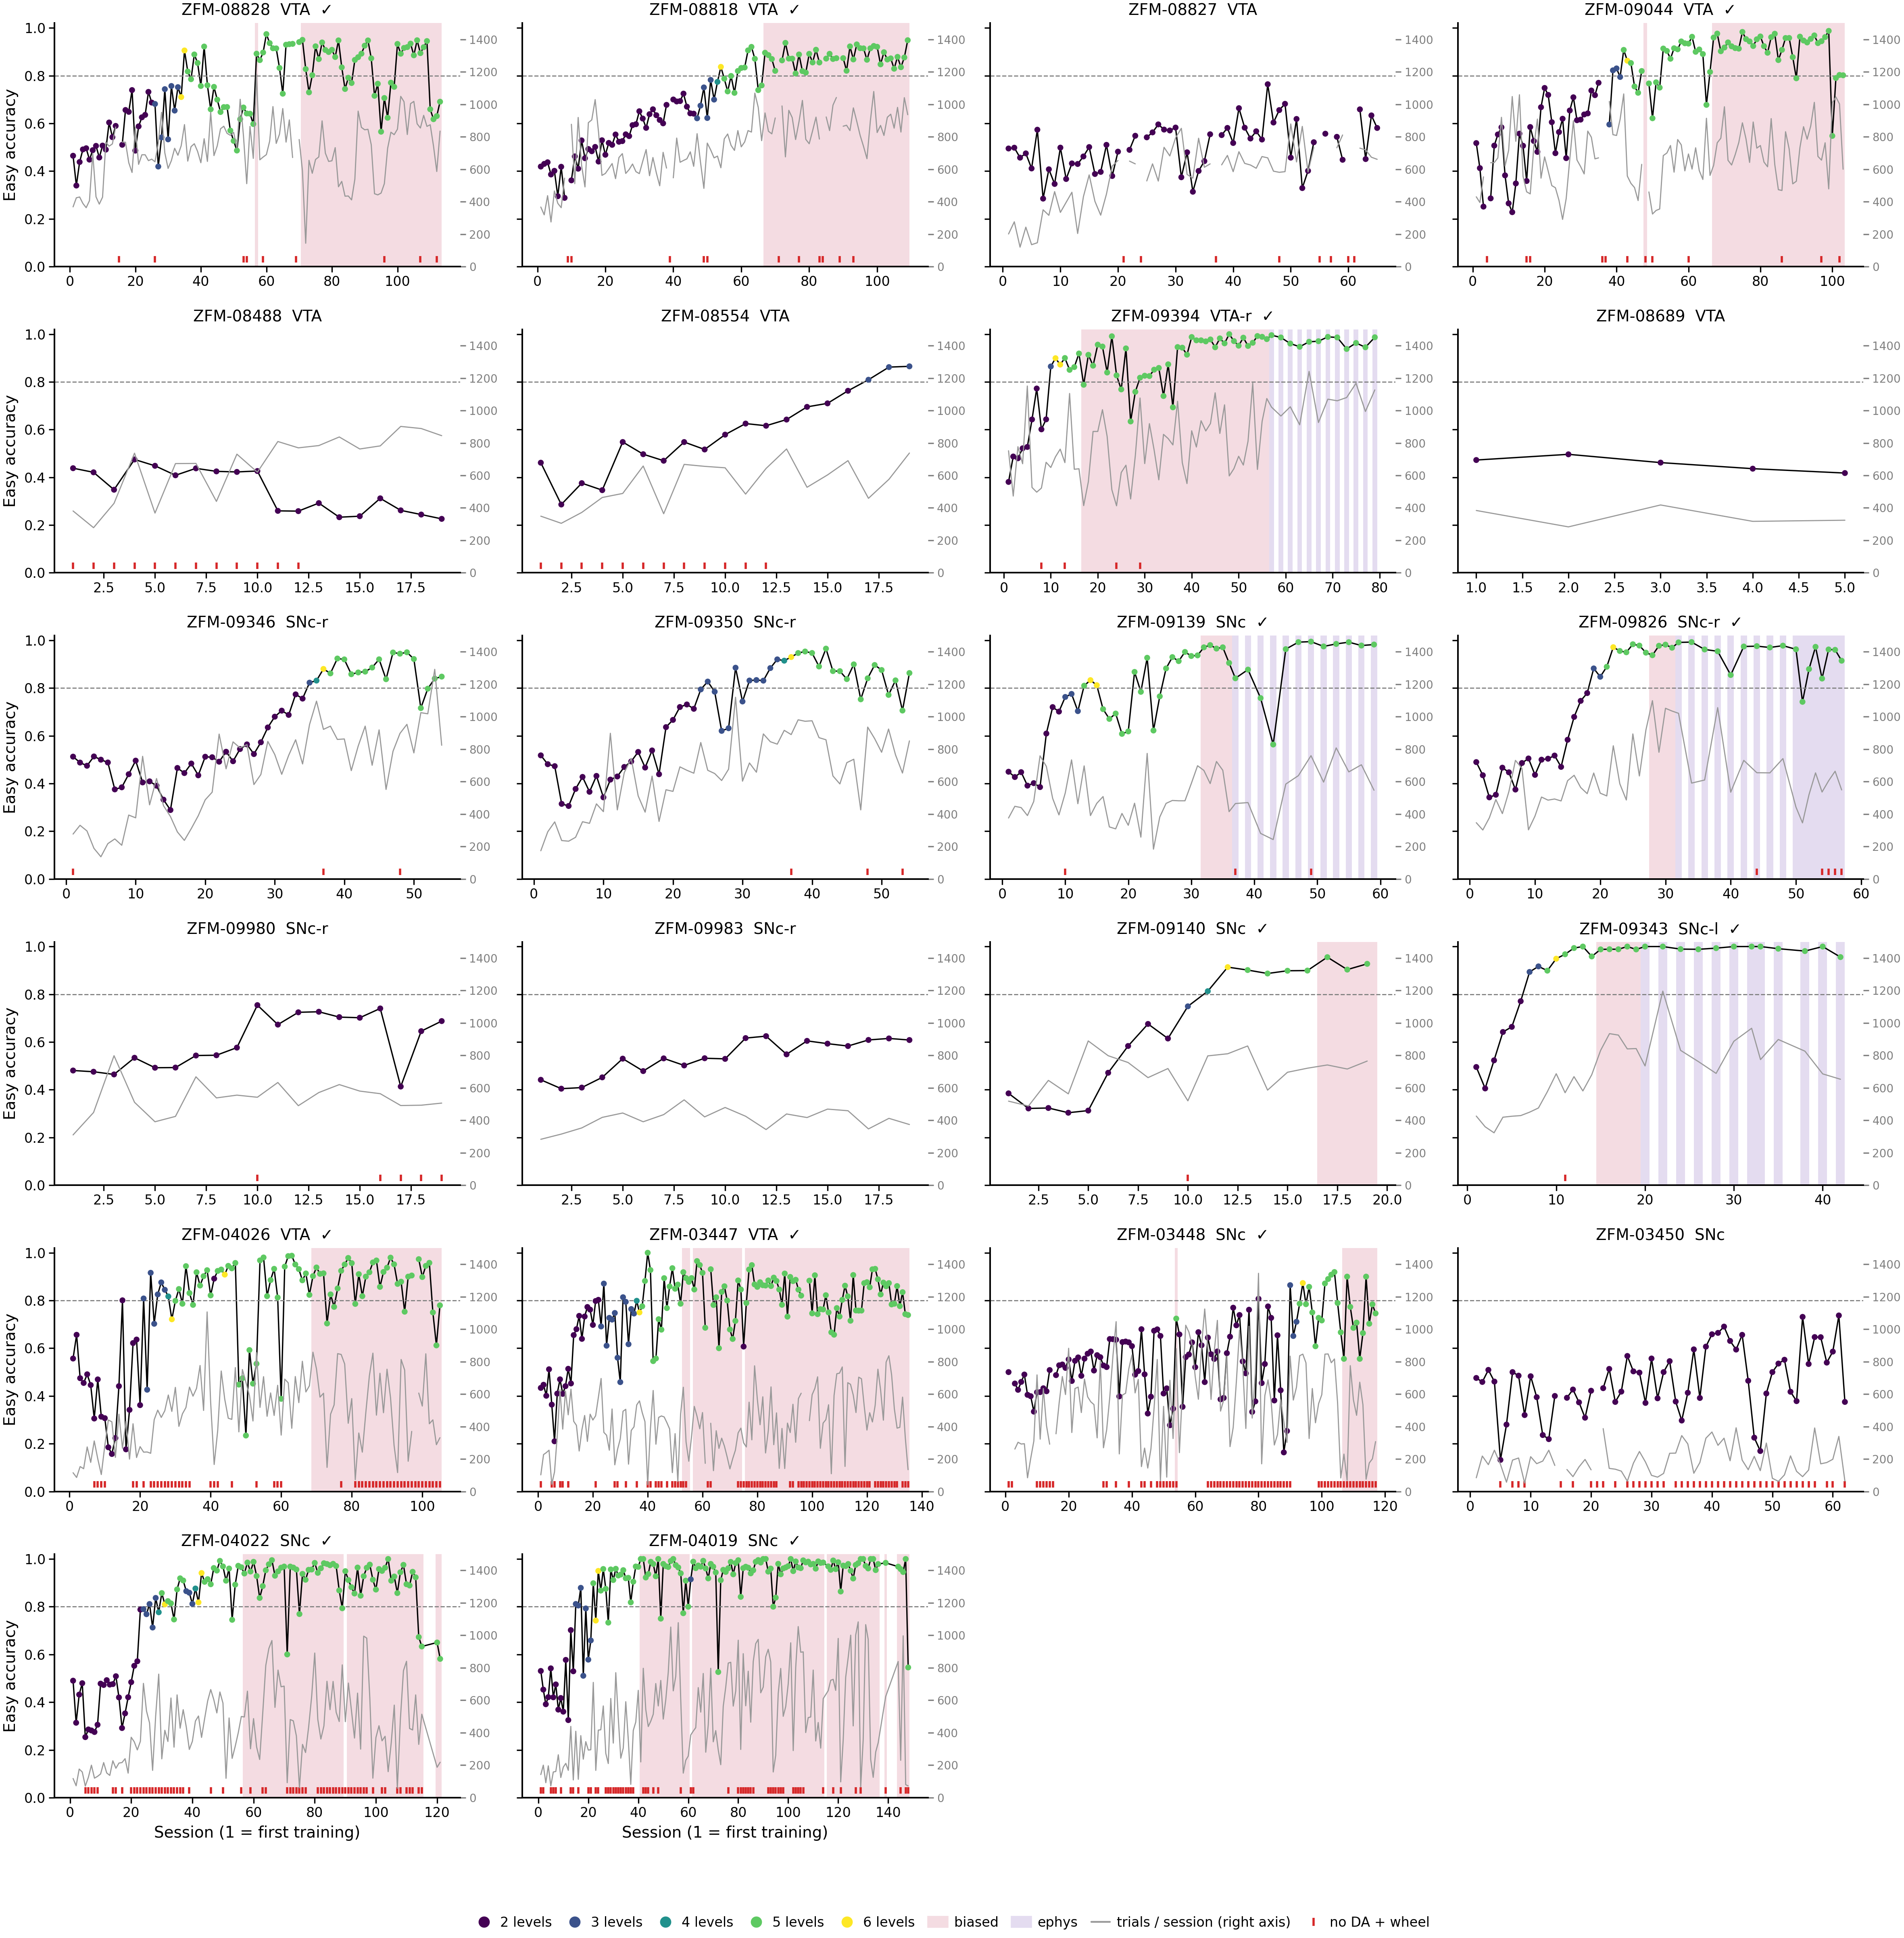

In [4]:
STAGE_CMAP = plt.get_cmap('viridis', 5)       # 2..6 contrasts
PROT_BG = {'biased': '#F4DCE2', 'ephys': '#E4DCF0'}
order = list(mice.index)
ncol = 4
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.0 * nrow), sharey=True, squeeze=False)
for ax, s in zip(axes.flat, order):
    g = D[(D['subject'] == s) & D['session_class'].isin(['training', 'biased', 'ephys'])]
    for x, pc in zip(g['x'], g['session_class']):
        if pc in PROT_BG:
            ax.axvspan(x - 0.5, x + 0.5, color=PROT_BG[pc], lw=0, zorder=0)
    ax.plot(g['x'], g['p_correct_easy'], color='k', lw=0.6, zorder=2)
    ax.scatter(g['x'], g['p_correct_easy'], c=g['n_contrasts'].clip(2, 6), cmap=STAGE_CMAP, vmin=1.5, vmax=6.5,
               s=7, lw=0, zorder=3)
    miss = g.loc[~g['da_wheel'], 'x']
    ax.plot(miss, np.full(len(miss), 0.03), '|', color='tab:red', ms=3, zorder=3)
    ax.axhline(0.8, color='0.5', ls='--', lw=0.5)
    ax2 = ax.twinx()
    ax2.plot(g['x'], g['n_trials'], color='0.6', lw=0.5)
    ax2.set_ylim(0, 1500); ax2.tick_params(labelsize=5, colors='0.5')
    ax.set_ylim(0, 1.02)
    ax.set_title(f"{s}  {mice.loc[s, 'target']}{'  ✓' if mice.loc[s, 'reached_biased'] else ''}", fontsize=7)
    ax.tick_params(labelsize=6)
for ax in axes.flat[len(order):]:
    ax.set_axis_off()
for ax in axes[:, 0]:
    ax.set_ylabel('Easy accuracy', fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('Session (1 = first training)', fontsize=7)
handles = ([Line2D([], [], marker='o', ls='', color=STAGE_CMAP(k - 2), ms=4, label=f'{k} levels') for k in range(2, 7)]
           + [Patch(color=v, label=k) for k, v in PROT_BG.items()]
           + [Line2D([], [], color='0.6', lw=0.8, label='trials / session (right axis)'),
              Line2D([], [], marker='|', ls='', color='tab:red', label='no DA + wheel')])
fig.legend(handles=handles, loc='lower center', ncol=9, frameon=False, fontsize=6, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 2. Learning curves together (training sessions only)

Easy accuracy over training sessions, one line per mouse (3-session running mean), the 2025–26 cohort. Colour = target (VTA / SNc); solid = reached biased, dotted = did not.

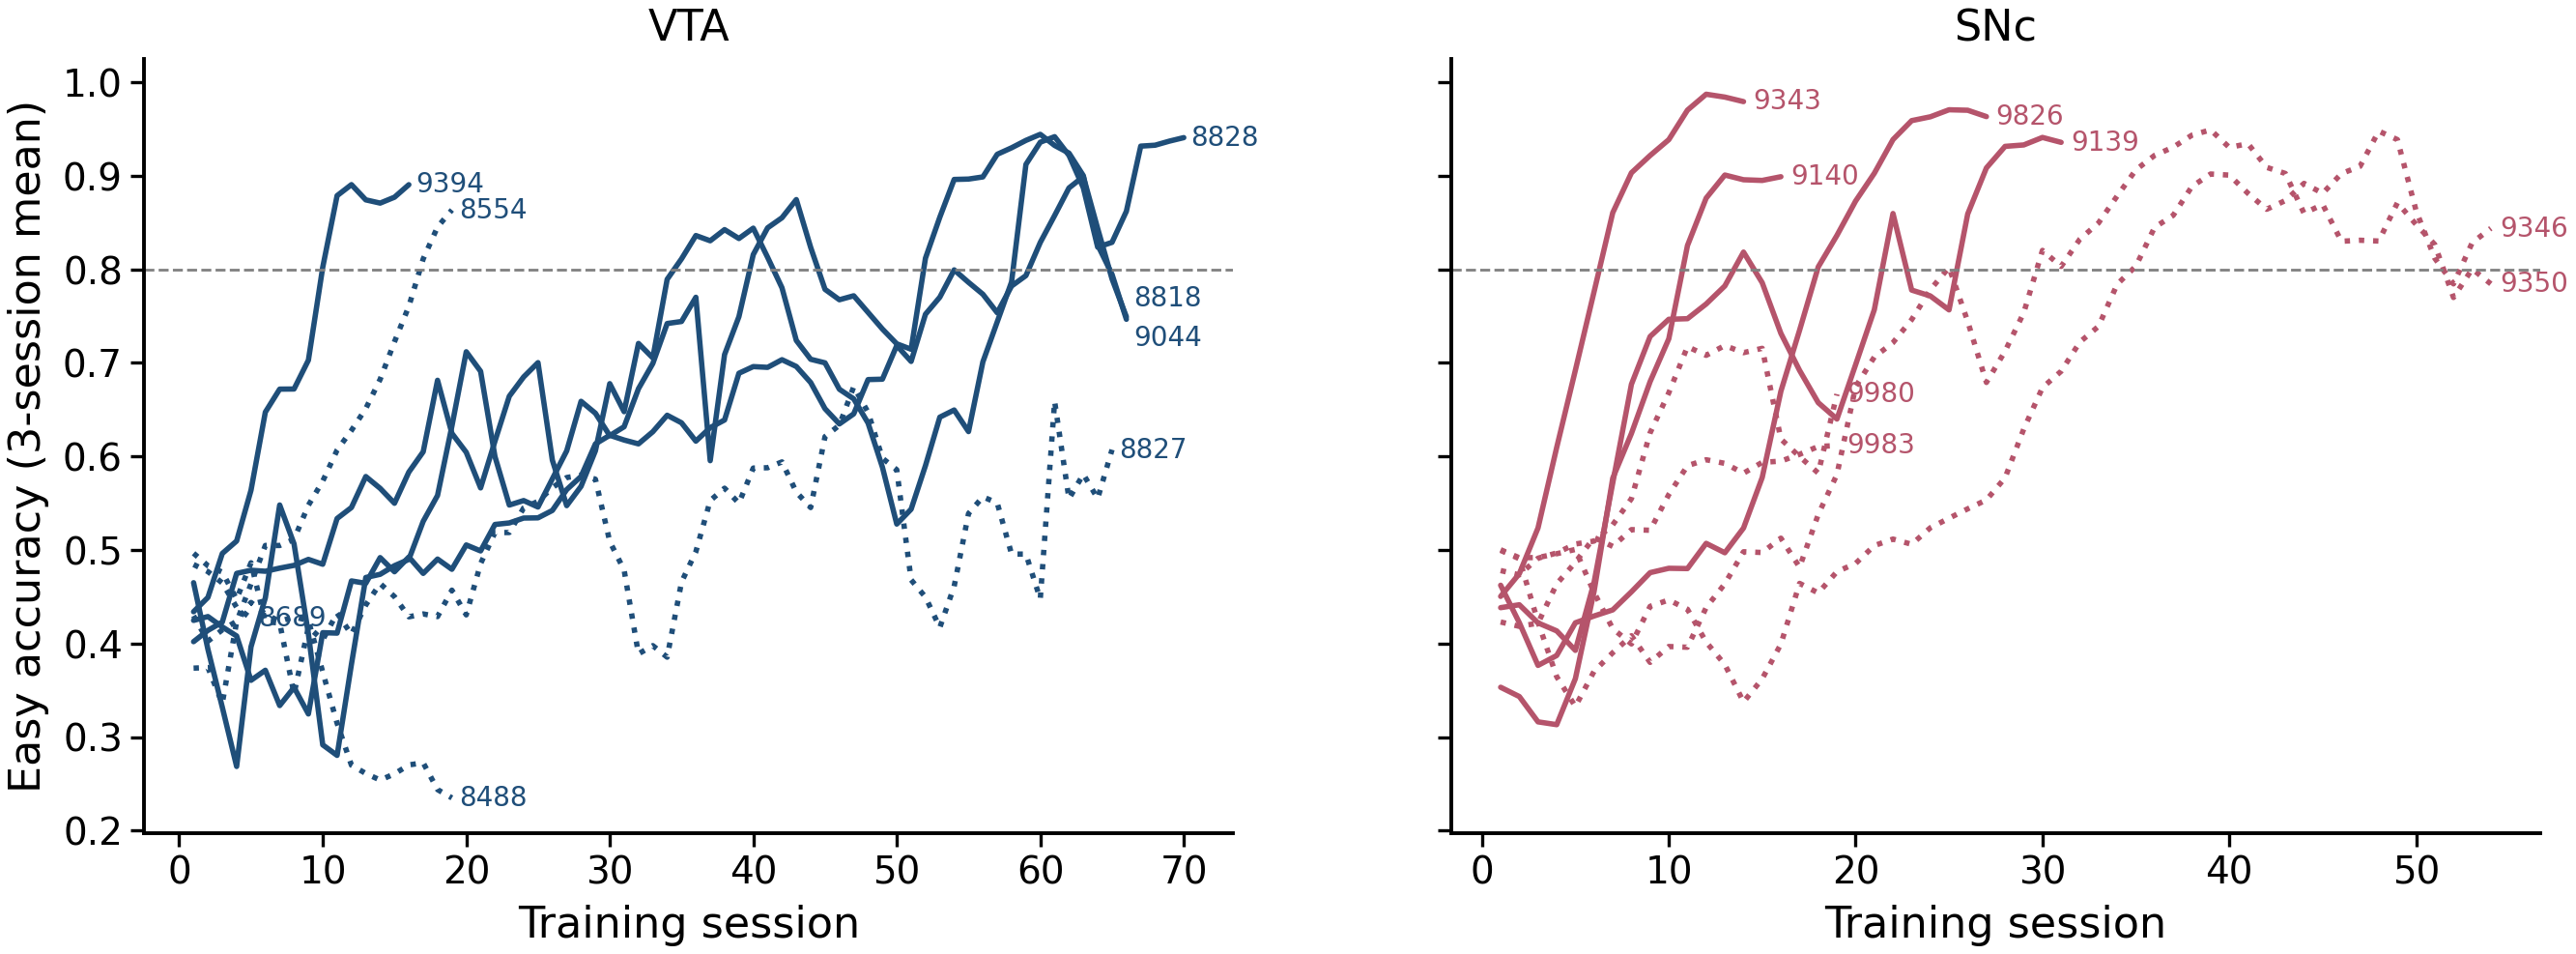

In [5]:
AREA_COL = {'VTA': '#1F4E79', 'SNc': '#B5546B'}
LABEL_NUDGE = {'ZFM-08818': 0.02, 'ZFM-09044': -0.02}   # their curves end at the same point
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, (area, col) in zip(axes, AREA_COL.items()):
    for s in mice.index[(mice['cohort'] == '2025-26') & (mice['area'] == area)]:
        g = D[(D['subject'] == s) & (D['session_class'] == 'training')].sort_values('x')
        y = g['p_correct_easy'].rolling(3, min_periods=1, center=True).mean()
        ax.plot(g['x'], y, color=col, lw=1, ls='-' if mice.loc[s, 'reached_biased'] else ':')
        ax.text(g['x'].iloc[-1] + 0.5, y.iloc[-1] + LABEL_NUDGE.get(s, 0), s[-4:], fontsize=5, color=col, va='center')
    ax.axhline(0.8, color='0.5', ls='--', lw=0.5)
    ax.set_title(area, fontsize=8); ax.set_xlabel('Training session')
axes[0].set_ylabel('Easy accuracy (3-session mean)')
plt.show()

## Summary

1. **The 2025–26 VTA mice are mostly slow learners.** ZFM-08828, 09044 and 08818 first reach 80 % easy accuracy at training sessions 35, 39 and 54. They climb gradually, with long plateaus and dips, over 65–69 training sessions before biased. ZFM-09394 is the fast exception (80 % at session 10, biased after 16).
2. **The VTA non-learner ZFM-08827 really doesn't learn.** Easy accuracy drifts from ~0.45 to ~0.6 over 65 sessions, and it never gets past the first stage (2 contrast levels). With full DA + wheel coverage, it is a real negative control.
3. **The SNc mice are faster.** ZFM-09343, 09140, 09139 and 09826 reach 80 % at sessions 7–19. ZFM-09346 and 09350 are slow (sessions 35 and 25) and reach the full contrast set, but never moved to biased. ZFM-09980 and 09983 are still at ~0.6–0.7 after 19 sessions.
4. **The short-recorded VTA mice:** ZFM-08488 gets worse over 19 sessions (0.45 → 0.25, a side bias?). ZFM-08554 learns steadily (80 % at session 17). ZFM-08689 stopped after 5.
5. **Stage regressions.** ZFM-08828 reaches 5–6 contrast levels around session 34, is back at 2 levels from ~40 to ~55, then climbs again. The same happens briefly in ZFM-04026. That means the protocol was restarted, so its "session" axis mixes two passes through training. Check the task settings before treating those sessions as one learning curve.
6. **For the DA analysis, this gives a spread of learning speeds within one area.** VTA has one fast learner, three slow ones and one non-learner, all with DA + wheel from session 1. The slow mice have long pre-criterion phases (30–50 sessions), which is what the pre-onset test needs.
